# Download of Sentinel-2 images

This notebook finds the Sentinel-2 Level-1C images of a period in the catalogue of the
[Copernicus Data Space Ecosystem](https://dataspace.copernicus.eu) (CDSE), by tile or by area, and downloads
them into the tree read by the batches of grstbx and GRS: `<odir>/<tile>/YYYY/MM/DD/<image>.SAFE`.

- the **search** uses the public OData catalogue of CDSE: no account is needed;
- the **download** uses the S3 interface of CDSE (bucket `eodata`), with the S3 keys of a CDSE account,
  created at https://eodata-s3keysmanager.dataspace.copernicus.eu. The keys are read from the
  `~/.s3cfg` file of s3cmd, from an AWS profile or from the environment: the notebook holds no key;
- each image is written to `<image>.SAFE.part` and renamed at the end, so an interrupted download leaves no
  incomplete image, and the images already on disk are skipped: run the download again to resume.

The functions are in `grstbx.download` (`pip install "grstbx[remote]"` for the download).

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd

from grstbx import download

odir = '/data/satellite/Sentinel-2/L1C'     # root of the Level-1C images

## 1. Search by tile

`download.search` returns one row per image: name, tile, acquisition time, cloud cover (%), size, S3 path.
When the archive holds several processings of the same acquisition (reprocessing of the archive with
another baseline), the last one is kept (`last_processing=False` keeps them all).

In [2]:
tiles = ['31TFJ']
start, end = '2024-07-01', '2024-08-31'
max_cloud_cover = 20      # %

images = download.search(tiles, start, end, max_cloud_cover=max_cloud_cover)
images['on_disk'] = download.on_disk(images, odir)
print(f'{len(images)} images, {images["size"].sum() / 1e9:.1f} GB, '
      f'{images.on_disk.sum()} already on disk')
images[['name', 'time', 'cloud_cover', 'on_disk']]

19 images, 15.1 GB, 19 already on disk


,name,time,cloud_cover,on_disk
0,S2A_MSIL1C_20240702T102601_N0510_R108_T31TFJ_2...,2024-07-02 10:26:01.024,0.574094,True
1,S2A_MSIL1C_20240705T104021_N0510_R008_T31TFJ_2...,2024-07-05 10:40:21.025,9.274455,True
2,S2B_MSIL1C_20240707T102559_N0510_R108_T31TFJ_2...,2024-07-07 10:25:59.024,6.693422,True
3,S2B_MSIL1C_20240710T103629_N0510_R008_T31TFJ_2...,2024-07-10 10:36:29.024,0.000000,True
4,S2B_MSIL1C_20240720T103629_N0510_R008_T31TFJ_2...,2024-07-20 10:36:29.024,2.854287,True
5,S2A_MSIL1C_20240722T103031_N0510_R108_T31TFJ_2...,2024-07-22 10:30:31.024,0.261135,True
6,S2A_MSIL1C_20240725T104021_N0511_R008_T31TFJ_2...,2024-07-25 10:40:21.024,0.000000,True
7,S2B_MSIL1C_20240727T102559_N0511_R108_T31TFJ_2...,2024-07-27 10:25:59.024,0.026144,True
8,S2B_MSIL1C_20240730T103629_N0511_R008_T31TFJ_2...,2024-07-30 10:36:29.024,0.835666,True
9,S2A_MSIL1C_20240801T103031_N0511_R108_T31TFJ_2...,2024-08-01 10:30:31.024,0.000000,True


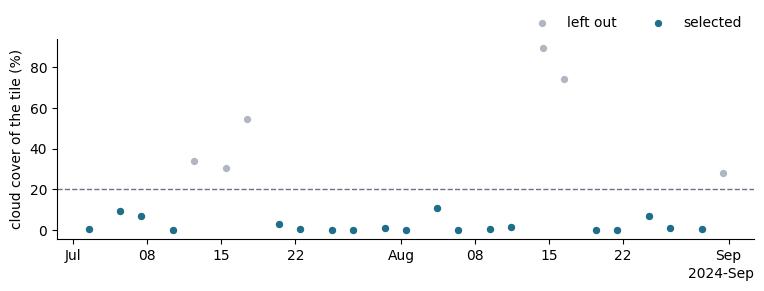

In [3]:
import matplotlib.dates as mdates

all_images = download.search(tiles, start, end)
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.scatter(all_images.time, all_images.cloud_cover, s=18, color='#b0b7c3', label='left out')
ax.scatter(images.time, images.cloud_cover, s=18, color='#1f6f8b', label='selected')
ax.axhline(max_cloud_cover, color='#6b7280', lw=1, ls='--')
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
ax.set_ylabel('cloud cover of the tile (%)')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, ncol=2, loc='upper right', bbox_to_anchor=(1, 1.18))
plt.show()

## 2. Search by area

With `area` (a box in longitude and latitude, or a shapely geometry), the catalogue returns the images whose
footprint intersects it, whatever their tile. Here the Gulf of Fos and the Étang de Berre, at the edge of
tiles 31TFJ and 31TFH: an image of each tile per overpass.

{'31TFH': 6, '31TFJ': 6}


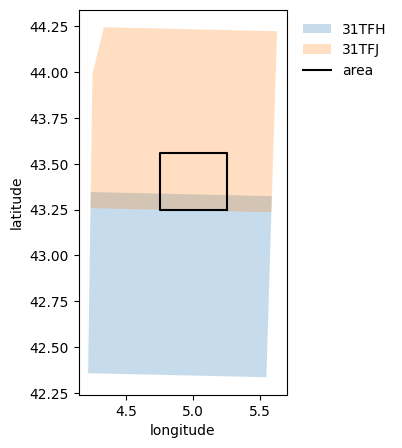

In [4]:
from shapely.geometry import box, shape

area = (4.75, 43.25, 5.25, 43.56)       # lon_min, lat_min, lon_max, lat_max
found = download.search(area=area, start='2024-07-01', end='2024-07-15')
print(found.groupby('tile').size().to_dict())

fig, ax = plt.subplots(figsize=(6.5, 5))
for tile, group in found.groupby('tile'):
    footprint = shape(group.footprint.iloc[0])
    ax.fill(*footprint.exterior.xy, alpha=0.25, label=tile)
ax.plot(*box(*area).exterior.xy, color='k', lw=1.5, label='area')
ax.set_xlabel('longitude')
ax.set_ylabel('latitude')
ax.set_aspect(1 / 0.73)       # cos(43 deg)
ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(1.02, 1))
plt.show()

## 3. Download

`download.download` copies each image from the S3 interface of CDSE, several images at a time (`workers`),
and returns a summary: `downloaded`, `exists` (already on disk) or `failed` (with the error; the other
images go on). The keys come from `download.cdse_storage_options()`: the `access_key` and `secret_key` of
`~/.s3cfg`, or `cdse_storage_options(profile='cdse')` for an AWS profile. A full tile is 0.6 to 0.9 GB:
set `run_download` to `True` to download the images of section 1.

In [5]:
run_download = False

storage_options = download.cdse_storage_options()
print('keys from ~/.s3cfg' if 'key' in storage_options else 'keys from the profile or the environment')

if run_download:
    summary = download.download(images, odir, storage_options=storage_options, workers=4)
    print(summary.status.value_counts().to_dict())
    print(summary[summary.status == 'failed'])

keys from ~/.s3cfg


### Same download with s3cmd

`download.s3cmd_commands` gives the `s3cmd sync` command of each image, to run from a shell, e.g. with
4 downloads at a time:

```bash
xargs -P 4 -I {} sh -c "{}" < l1c_download_commands.sh
```

In [6]:
commands = download.s3cmd_commands(images[~images.on_disk], odir)
print(*commands[:2], sep='\n')
# with open('l1c_download_commands.sh', 'w') as f:
#     f.write('\n'.join(commands) + '\n')

## 4. Next step: the batch processing

The images are in the tree read by `grstbx.batch.list_images`, with their cloud cover read from their
metadata: they are the input of the batch notebooks (see the batch processing tutorial).

In [7]:
from grstbx import batch

level1 = batch.list_images(odir, tiles).loc[start:end]
print(f'{len(level1)} images of {", ".join(tiles)} on disk from {start} to {end}')
level1[['name', 'cloud_cover']].head()

23 images of 31TFJ on disk from 2024-07-01 to 2024-08-31


,name,cloud_cover
date,,
2024-07-02,S2A_MSIL1C_20240702T102601_N0510_R108_T31TFJ_2...,0.005741
2024-07-05,S2A_MSIL1C_20240705T104021_N0510_R008_T31TFJ_2...,0.092745
2024-07-07,S2B_MSIL1C_20240707T102559_N0510_R108_T31TFJ_2...,0.066934
2024-07-10,S2B_MSIL1C_20240710T103629_N0510_R008_T31TFJ_2...,0.000000
2024-07-12,S2A_MSIL1C_20240712T102601_N0510_R108_T31TFJ_2...,0.338995
